# Módulo 02 · Notebook 2: CRISP-DM, comprensión del negocio y de los datos

CRISP-DM es una metodología: una guía de pasos para hacer un proyecto de datos de principio a fin sin perderse en el camino. El nombre viene del inglés Cross-Industry Standard Process for Data Mining, que se traduce como “proceso estándar, para cualquier industria, para la minería de datos”. Se creó a finales de los años 90 entre varias empresas y sigue siendo la más usada, porque sirve para cualquier sector (banca, salud, comercio) y parte siempre del negocio, no de la tecnología.


| Fase | Pregunta que responde | Ejemplo con la inmobiliaria |
|---|---|---|
| **1. Comprensión del negocio** | ¿Qué problema resolvemos y cómo sabremos que lo logramos? | "Queremos avalúos rápidos con un error menor al 15 %" |
| **2. Comprensión de los datos** | ¿Qué datos tenemos y qué tan buenos son? | 1.460 ventas, 81 columnas, nulos que significan "no tiene" |
| **3. Preparación de los datos** | ¿Cómo los dejamos listos para analizar? | Rellenar nulos, quitar errores, crear la edad de la casa |
| **4. Modelado** | ¿Qué modelo usamos? | Una regresión que estima el precio |
| **5. Evaluación** | ¿Cumple el objetivo del negocio? | ¿El error quedó por debajo del 15 %? |
| **6. Despliegue** | ¿Cómo lo usa alguien en el día a día? | Una aplicación donde el asesor consulta el precio estimado |

> **Es un ciclo, no una escalera:** volver a una fase anterior es normal y es parte del método, e.g si al modelar descubren que falta una variable, regresan a los datos. Si la evaluación muestra que el modelo no sirve para el negocio, regresan al problema. Volver atrás no es un error, es parte del método..

En este notebook recorremos las dos primeras fases de CRISP-DM con el caso de la **inmobiliaria**:

1. **Comprensión del negocio:** ¿qué problema resolvemos y cómo sabremos que lo logramos?
2. **Comprensión de los datos:** ¿qué tenemos, qué tan bueno es y qué hipótesis nos sugiere?




---
## Fase 1: Comprensión del negocio

**Contexto:** la inmobiliaria tarda en promedio 5 días en hacer un avalúo, porque un perito visita la casa. Los clientes se van con la competencia, que responde el mismo día.

| Nivel | Definición |
|---|---|
| **Problema de negocio** | Dar un precio de referencia en minutos, no en días |
| **Objetivo de ciencia de datos** | Modelo de **regresión** que estime `SalePrice` a partir de las características de la casa |
| **Criterio de éxito (negocio)** | El 80 % de los avalúos automáticos quedan a menos de ±15 % del avalúo del perito |
| **Criterio de éxito (modelo)** | MAPE < 15 % en datos que el modelo no ha visto, y mejor que el *baseline* |
| **Riesgos** | Casas atípicas (mansiones, remates), datos de 2006-2010 (¿siguen vigentes?), barrios con pocas ventas |

* MAPE es el error porcentual promedio de un modelo: en promedio, ¿en qué porcentaje se equivoca?

> El criterio de éxito **se define ANTES de modelar**. Si no, cualquier resultado "parece bueno".

---
## Fase 2: Comprensión de los datos

### 2.1 Cargar y mirar

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from intro_analitica.datos import cargar_house_prices, leer_diccionario_house_prices
from intro_analitica.eda import perfil_rapido

sns.set_theme(style="whitegrid")
df = cargar_house_prices()

print(f"Filas: {df.shape[0]:,} · Columnas: {df.shape[1]}")
df.head()

Filas: 1,460 · Columnas: 81


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


**¿Qué representa una fila?** Una **venta** de una casa. Es la primera pregunta que hay que responder siempre:
de ella depende cómo se agrupa, qué es un duplicado y qué se puede predecir.

### 2.2 El diccionario de datos

Con 81 columnas no podemos adivinar qué es `BsmtFinType2`. El archivo `data_description.txt` lo explica.
La función `leer_diccionario_house_prices()` lo convierte en un diccionario de Python.

In [2]:
diccionario = leer_diccionario_house_prices()
for columna in ["SalePrice", "OverallQual", "GrLivArea", "PoolQC", "Alley", "BsmtFinType2"]:
    print(f"{columna:<14} → {diccionario.get(columna, '(no está en el diccionario)')}")

SalePrice      → (no está en el diccionario)
OverallQual    → Rates the overall material and finish of the house
GrLivArea      → Above grade (ground) living area square feet
PoolQC         → Pool quality
Alley          → Type of alley access to property
BsmtFinType2   → Rating of basement finished area (if multiple types)


`SalePrice` no aparece en el diccionario porque es el **target** (la competencia de Kaggle lo documenta aparte).

Y mira lo que dice el diccionario sobre los códigos de `PoolQC`:

In [3]:
from intro_analitica import config

texto = config.HOUSE_PRICES_DESCRIPCION.read_text(encoding="utf-8")
inicio = texto.find("PoolQC")
print(texto[inicio : inicio + 160])

PoolQC: Pool quality
		
       Ex	Excellent
       Gd	Good
       TA	Average/Typical
       Fa	Fair
       NA	No Pool
		
Fence: Fence quality
		
       GdPrv	Go


**`NA = No Pool`.** Esto será clave en el módulo 03: muchos "nulos" **no son datos perdidos**, significan "no tiene".

### 2.3 Tipos de variables

In [4]:
tipos = df.dtypes.astype(str).value_counts()
print(tipos)

numericas = df.select_dtypes("number").columns.drop(["Id", "SalePrice"])
categoricas = df.select_dtypes(exclude="number").columns
print(f"\nNuméricas: {len(numericas)} · Categóricas: {len(categoricas)}")

str        43
int64      35
float64     3
Name: count, dtype: int64

Numéricas: 36 · Categóricas: 43


**Ojo:** que pandas diga "número" no significa que la variable sea **cuantitativa**:
- `MSSubClass` (tipo de vivienda) usa códigos 20, 30, 60… pero es **categórica**: 60 no es "el triple" de 20.
- `OverallQual` (1-10) es **ordinal**: hay orden, pero la distancia entre 1 y 2 no es necesariamente igual a la que hay entre 9 y 10.

In [5]:
df[["MSSubClass", "OverallQual"]].nunique()

MSSubClass     15
OverallQual    10
dtype: int64

### 2.4 Perfil rápido: nulos y cardinalidad

`perfil_rapido` (de `src/intro_analitica/eda.py`) responde en una tabla: tipo, nulos, % de nulos, valores únicos y un ejemplo.

In [6]:
perfil = perfil_rapido(df)
perfil[perfil["nulos"] > 0]

,tipo,nulos,pct_nulos,unicos,ejemplo
PoolQC,str,1453,99.5,3,Ex
MiscFeature,str,1406,96.3,4,Shed
Alley,str,1369,93.8,2,Grvl
Fence,str,1179,80.8,4,MnPrv
MasVnrType,str,872,59.7,3,BrkFace
FireplaceQu,str,690,47.3,5,TA
LotFrontage,float64,259,17.7,110,65.0
GarageYrBlt,float64,81,5.5,97,2003.0
GarageType,str,81,5.5,6,Attchd
GarageQual,str,81,5.5,5,TA


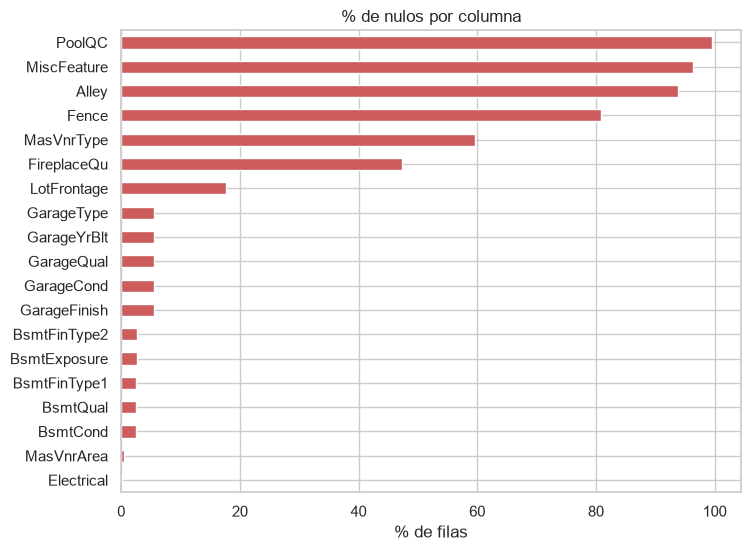

In [7]:
con_nulos = perfil[perfil["nulos"] > 0]["pct_nulos"].sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
con_nulos.plot(kind="barh", ax=ax, color="indianred")
ax.set(title="% de nulos por columna", xlabel="% de filas")
plt.show()

**Lectura:** 19 columnas tienen nulos. Hay tres grupos:

| Grupo | Columnas | ¿Qué significa probablemente? |
|---|---|---|
| Casi todo nulo (>80 %) | `PoolQC`, `MiscFeature`, `Alley`, `Fence` | La casa **no tiene** esa característica |
| Familias de columnas | `Garage*` (81), `Bsmt*` (37-38) | Casas sin garaje o sin sótano: los nulos aparecen **juntos** |
| Pocos nulos sueltos | `Electrical` (1), `MasVnrArea` (8) | Datos realmente perdidos |

In [8]:
# ¿Los nulos de garaje aparecen juntos? Si sí, es la misma casa "sin garaje".
columnas_garaje = ["GarageType", "GarageFinish", "GarageQual", "GarageCond", "GarageYrBlt"]
print("Filas con algún nulo de garaje :", df[columnas_garaje].isna().any(axis=1).sum())
print("Filas con TODOS nulos de garaje:", df[columnas_garaje].isna().all(axis=1).sum())
print("De esas, ¿cuántas tienen GarageArea = 0?:", (df.loc[df[columnas_garaje].isna().all(axis=1), "GarageArea"] == 0).sum())

Filas con algún nulo de garaje : 81
Filas con TODOS nulos de garaje: 81
De esas, ¿cuántas tienen GarageArea = 0?: 81


Confirmado: las 81 casas con nulos de garaje tienen `GarageArea = 0`. **No tienen garaje.**

### 2.5 La variable objetivo (target)

count      1,460
mean     180,921
std       79,443
min       34,900
25%      129,975
50%      163,000
75%      214,000
max      755,000
Name: SalePrice, dtype: str


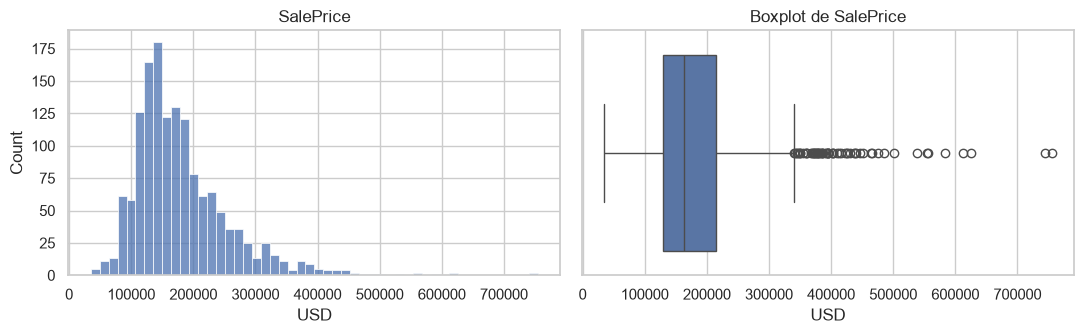

In [9]:
print(df["SalePrice"].describe().apply("{:,.0f}".format))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df["SalePrice"], bins=50, ax=axes[0])
axes[0].set(title="SalePrice", xlabel="USD")
sns.boxplot(x=df["SalePrice"], ax=axes[1])
axes[1].set(title="Boxplot de SalePrice", xlabel="USD")
plt.tight_layout()
plt.show()

El precio tiene **asimetría a la derecha** (cola larga de casas caras). Lo tendremos en cuenta al modelar: el error en las casas caras pesa mucho en el RMSE.

### 2.6 Primeras relaciones (solo para generar hipótesis)

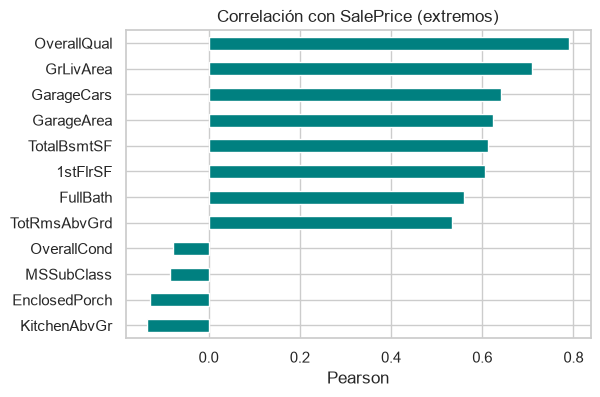

In [10]:
correlaciones = df[numericas.tolist() + ["SalePrice"]].corr()["SalePrice"].drop("SalePrice").sort_values()
fig, ax = plt.subplots(figsize=(6, 4))
pd.concat([correlaciones.head(4), correlaciones.tail(8)]).plot(kind="barh", ax=ax, color="teal")
ax.set(title="Correlación con SalePrice (extremos)", xlabel="Pearson")
plt.show()

- En la anterior gráfica, cada barra mide qué tan fuerte es la relación lineal de una variable numérica con el precio. Muestra las 8 variables más relacionadas de forma positiva y las 4 más negativas. La Calidad de la casa y el área dominan. Las dos más fuertes son la calidad general (OverallQual, 0,79) y el área habitable (GrLivArea, 0,71). Las siguen el garaje, el sótano, el primer piso, los baños y las habitaciones, todas entre 0,53 y 0,64. Casi todas miden lo mismo: qué tan grande es la casa.

- Hay variables que tienen su pareja y miden casi lo mismo, e.g GarageCars (cupos del garaje)	GarageArea (área del garaje) , GrLivArea (área habitable)	TotRmsAbvGrd (número de habitaciones) y TotalBsmtSF (área del sótano) 1stFlrSF (área del primer piso). 

- Tiene sentido afirmar que un garaje para más carros es más grande. Esto se llama multicolinealidad. Para el modelo, conviene usar solo una de cada pareja, porque la otra no agrega información nueva.

- Lo que más se relaciona con el precio es la calidad y el tamaño de la casa. Pero ojo: varias de estas variables miden casi lo mismo, y algunas relaciones que parecen raras, como que una casa en mejor estado valga menos, se explican por otra variable: la antigüedad. La correlación es un punto de partida para hacer preguntas, no una conclusión.

### 2.7 Problemas detectados e hipótesis (entregable de la fase 2)

**Problemas de calidad**
1. 19 columnas con nulos; la mayoría significa "no tiene" (piscina, garaje, sótano…).
2. Variables numéricas que en realidad son categóricas (`MSSubClass`).
3. Target asimétrico, con casas muy caras.
4. Los datos son de 2006-2010: ¿siguen representando el mercado actual? (**riesgo de vigencia**).

**Hipótesis**
- H1: la **calidad general** (`OverallQual`) es el factor que más explica el precio (correlación ≈ 0.79).
- H2: a mayor **área habitable** (`GrLivArea`), mayor precio, pero con *outliers* (casas enormes y baratas).
- H3: el **barrio** influye aun cuando se compara por calidad y área.
- H4: las casas **remodeladas** recientemente se venden más caras que otras de la misma edad.

Estas hipótesis se validan en el EDA del **módulo 03**.

---
## Actividad puente al módulo 03: ¿qué harías con estos datos?

Del material del profesor: una tabla pequeña pero **sucia**. En parejas, identifiquen **todos** los problemas antes de mirar la solución.

In [11]:
ventas_sucias = pd.DataFrame(
    {
        "ID": [1, 2, 3, 4],
        "Fecha": ["2023/12/05", "12-06-23", "2023/12/07", "2023/12/05"],
        "Precio": [59.99, None, -15, 89.90],
        "Cliente": ["Juan P.", "Maria G", None, "Carlos S."],
        "Ciudad": ["Bogotá", "Bta", "Medellin", "bogotá"],
    }
)
ventas_sucias

,ID,Fecha,Precio,Cliente,Ciudad
0,1,2023/12/05,59.99,Juan P.,Bogotá
1,2,12-06-23,NaN,Maria G,Bta
2,3,2023/12/07,-15.00,NaN,Medellin
3,4,2023/12/05,89.90,Carlos S.,bogotá


<details>
<summary>Ver los problemas (¡primero piénsalo!)</summary>

| Columna | Problema | Qué haríamos |
|---|---|---|
| `Fecha` | Dos formatos (`AAAA/MM/DD` y `MM-DD-AA`) | Convertir a `datetime` con el formato correcto |
| `Precio` | Un nulo y un **negativo** (-15) | ¿Devolución o error de digitación? Preguntar al negocio. Imputar o eliminar |
| `Cliente` | Un nulo; puntos inconsistentes ("Maria G" vs "Juan P.") | "Desconocido"; normalizar el texto |
| `Ciudad` | "Bogotá", "Bta" y "bogotá" son la misma ciudad; falta la tilde en "Medellin" | Diccionario de mapeo y minúsculas/mayúsculas consistentes |

Esto es exactamente lo que haremos en el **módulo 03**.
</details>